# Stage 2 – Baseline EfficientNetB0 & Initial Fine-Tuning

In [3]:

from tensorflow import keras
from tensorflow.keras import layers

                                            
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

                                    
base_model.trainable = False

                                
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    5,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [4]:

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)


Epoch 1/10


2026-10-13 19:53:40.823880: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:53:40.966658: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:53:41.315557: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:53:41.458266: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:53:42.269128: E external/local_xla/xla/stream_

140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2897 - loss: 1.6534

2026-10-13 19:54:00.676063: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:00.811611: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:01.133206: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:01.274857: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:02.051599: E external/local_xla/xla/stream_

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.2902 - loss: 1.6525

2026-10-13 19:54:21.758200: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:21.901142: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:22.248020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:22.391181: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 19:54:23.212254: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 1.48500, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 67s 273ms/step - accuracy: 0.3589 - loss: 1.5244 - val_accuracy: 0.4366 - val_loss: 1.4850 - learning_rate: 1.0000e-04
Epoch 2/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4721 - loss: 1.3492
Epoch 2: val_loss improved from 1.48500 to 1.31178, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.4823 - loss: 1.3000 - val_accuracy: 0.5048 - val_loss: 1.3118 - learning_rate: 1.0000e-04
Epoch 3/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5348 - loss: 1.2103
Epoch 3: val_loss improved from 1.31178 to 1.19158, saving model to /kaggle/working/best_efficientnet_b0.keras

Epoch 3: finished saving model to /kaggle/wo

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 312ms/step
                  precision    recall  f1-score   support

           No DR       0.87      0.95      0.91       361
            Mild       0.75      0.08      0.15        74
        Moderate       0.67      0.27      0.38       200
          Severe       0.26      0.44      0.32        39
Proliferative DR       0.23      0.73      0.35        59

        accuracy                           0.63       733
       macro avg       0.56      0.49      0.42       733
    weighted avg       0.72      0.63      0.61       733



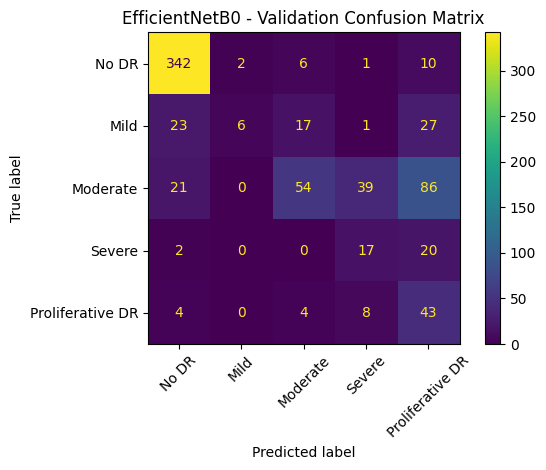

In [5]:

import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

                           
best_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0.keras"
)

                               
y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)
plt.title("EfficientNetB0 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [6]:

from tensorflow import keras

                                                   
model_ft = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0.keras"
)

                                        
base_model_ft = model_ft.get_layer("efficientnetb0")

                   
base_model_ft.trainable = True

                                                 
for layer in base_model_ft.layers[:-30]:
    layer.trainable = False

                                                               
for layer in base_model_ft.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:",
      sum(layer.trainable for layer in base_model_ft.layers))

                                             
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_ft = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

history_ft = model_ft.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks_ft
)


Trainable layers: 23
Epoch 1/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.6663 - loss: 0.8294
Epoch 1: val_loss improved from None to 0.81879, saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 52s 209ms/step - accuracy: 0.6565 - loss: 0.8320 - val_accuracy: 0.6739 - val_loss: 0.8188 - learning_rate: 1.0000e-05
Epoch 2/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6940 - loss: 0.7829
Epoch 2: val_loss improved from 0.81879 to 0.80889, saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_finetuned.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.6828 - loss: 0.7763 - val_accuracy: 0.6794 - val_loss: 0.8089 - learning_rate: 1.0000e-05
Epoch 3/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7037 - loss: 0.7427
Epoch 3: va

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 332ms/step
                  precision    recall  f1-score   support

           No DR       0.93      0.96      0.95       361
            Mild       0.47      0.28      0.35        74
        Moderate       0.70      0.56      0.62       200
          Severe       0.32      0.46      0.38        39
Proliferative DR       0.36      0.61      0.45        59

        accuracy                           0.73       733
       macro avg       0.55      0.57      0.55       733
    weighted avg       0.74      0.73      0.73       733



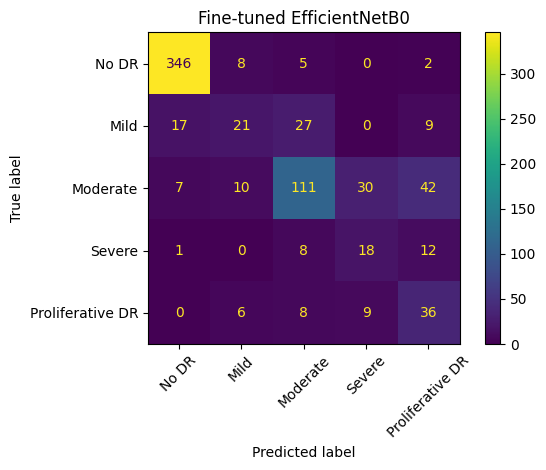

In [7]:

import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_ft = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_finetuned.keras"
)

y_prob_ft = best_ft.predict(val_ds, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred_ft,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred_ft,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)
plt.title("Fine-tuned EfficientNetB0")
plt.tight_layout()
plt.show()


In [9]:
for layer in model_ft.layers:
    print(layer.name, type(layer).__name__)

input_layer_1 InputLayer
efficientnetb0 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense
